In [1]:
import xarray as xr
from pystac_client import Client
catalog = Client.open("https://eoapi.workspace.earthcode.eox.at/stac/")
item_coll = list(catalog.search(collections=["agricemchimeds3v1"]).items())

In [2]:
for index, candidate in enumerate(item_coll):
    print(f"{index}: {candidate.id} - {candidate.properties.get('description', '')}")

0: agricem-data - This collection is part of the representative dataset of the Sentinel User Preparation project AgriCEM. The goal of AgriCEM is to develop stress indicators for sugar beet crops based on CHIME and LSTM data. This collection contains simulated CHIME L2A data showing an agricultural site containing sugar beet fields with different types of simulated stress. The dataset was generated using the SCOPE model for the bottom-of-atmosphere reference signal and the RISE simulator for the satellite data products. The spatial coverage is a 2x2 km patch close to Selhausen, Germany. The temporal coverage spans over the sugar beet growing season with weekly measurements for a total of 24 scenes from May to October 2021.


In [ ]:
items = {candidate.id: candidate for candidate in item_coll}
item = items["agricem-data"]
item

<Item id=agricem-data>

In [ ]:
item.assets["data"].href

In [2]:
asset = item.assets["data"]
ds = xr.open_zarr(asset.href.replace("s3://", asset.extra_fields["s3:endpoint_url"] + "/", 1))
ds

<xarray.Dataset> Size: 197MB
Dimensions:      (time: 24, y: 64, x: 64)
Coordinates:
  * time         (time) datetime64[ns] 192B 2021-05-19 2021-05-26 ... 2021-10-27
  * y            (y) float64 512B 5.633e+06 5.633e+06 ... 5.631e+06 5.631e+06
  * x            (x) float64 512B 7.595e+05 7.595e+05 ... 7.613e+05 7.614e+05
    spatial_ref  int64 8B ...
Data variables: (12/250)
    b001         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b002         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b003         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b004         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b005         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b006         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    ...           ...
    b245         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b246         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b247         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b248         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b249         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    b250         (time, y, x) float64 786kB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
Attributes:
    AREA_OR_POINT:       Area
    add_offset:          0.0
    center_wavelengths:  [404.2, 412.6, 421.0, 429.4, 437.8, 446.2, 454.6, 46...
    open_params:         {\n  "bbox": [\n    759465.0,\n    5631245.0,\n    7...
    scale_factor:        1.0
    stac_catalog:        C:\Users\m.spagnolli\repositories\agricem-intern\dat...
    stac_items:          {\n  "2021-05-19T00:00:00": [\n    "C:\\Users\\m.spa...
    xcube_eopf_version:  0.1.0

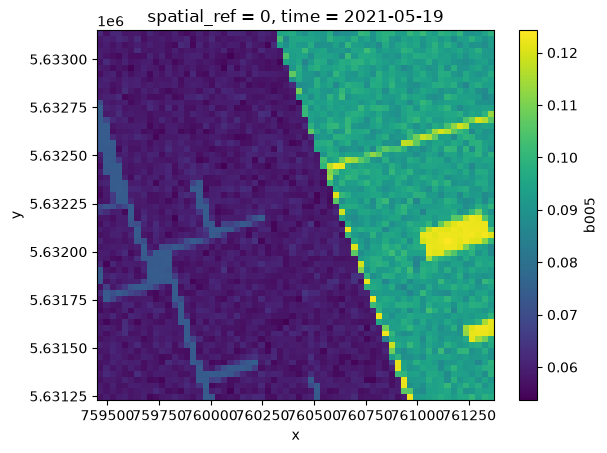

In [2]:
ds.b005.isel(time=0).plot()